# Planar dielectric optics
Reflection, refraction, Brewster angle, total internal reflection and polarization at a single dielectric boundary.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import vecdiff_general as optics
from numpy.testing import assert_allclose

%matplotlib inline

plt.rcParams.update(
    {
        "figure.figsize": (10, 4),
        "figure.dpi": 180,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.size": 11,
    }
)

um = 1e-6
wavelength = 0.532 * um

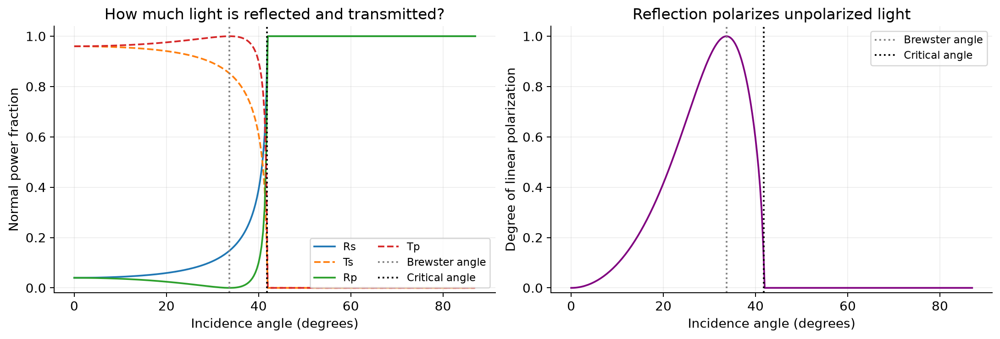

Brewster angle: 33.69°; critical angle: 41.81°


In [2]:
glass = optics.HomogeneousRegion("glass", optics.Dielectric(1.5))
air = optics.HomogeneousRegion("air", optics.Dielectric(1.0))
interface = optics.PlanarInterface(optics.Frame(), glass, air)

n1, n2 = glass.material.n, air.material.n
brewster = np.arctan(n2 / n1)
critical = np.arcsin(n2 / n1)


def plane_wave(angle, polarization="s"):
    direction = np.array([np.sin(angle), 0, np.cos(angle)])
    electric = (
        np.array([0, 1, 0])
        if polarization == "s"
        else np.array([np.cos(angle), 0, -np.sin(angle)])
    )

    return optics.PlaneWaveExpansion(
        [2 * np.pi * n1 / wavelength * direction],
        [electric],
        [0, 0, 0],
        wavelength,
        glass,
    )


probe = optics.PointGrid([[0, 0, 0]])
angles = np.unique(np.r_[np.linspace(0, 87, 260) * np.pi / 180, brewster])
reflectance, transmittance = {}, {}

for polarization in ("s", "p"):
    reflected_power, transmitted_power = [], []

    for angle in angles:
        source = plane_wave(angle, polarization)
        solution = optics.scatter_plane(source, interface)
        incident_flux = source.evaluate(probe).poynting()[0, 2]
        reflected_flux = solution.reflected.evaluate(probe).poynting()[0, 2]
        transmitted_flux = solution.transmitted.evaluate(probe).poynting()[0, 2]

        reflected_power.append(-reflected_flux / incident_flux)
        transmitted_power.append(transmitted_flux / incident_flux)

    reflectance[polarization] = np.array(reflected_power)
    transmittance[polarization] = np.array(transmitted_power)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")

for polarization in ("s", "p"):
    axes[0].plot(
        np.degrees(angles), reflectance[polarization], label=f"R{polarization}"
    )
    axes[0].plot(
        np.degrees(angles), transmittance[polarization], "--", label=f"T{polarization}"
    )

# An unpolarized source is an incoherent equal mixture of s and p, not a Jones vector.
Rs, Rp = reflectance["s"], reflectance["p"]
linear_polarization = np.abs(Rs - Rp) / (Rs + Rp)
axes[1].plot(np.degrees(angles), linear_polarization, color="purple")

for ax in axes:
    ax.axvline(np.degrees(brewster), color="gray", ls=":", label="Brewster angle")
    ax.axvline(np.degrees(critical), color="black", ls=":", label="Critical angle")
    ax.set(xlabel="Incidence angle (degrees)", ylim=(-0.02, 1.04))
    ax.grid(alpha=0.2)

axes[0].set(
    ylabel="Normal power fraction", title="How much light is reflected and transmitted?"
)
axes[1].set(
    ylabel="Degree of linear polarization",
    title="Reflection polarizes unpolarized light",
)
axes[0].legend(ncol=2, fontsize=9)
axes[1].legend(fontsize=9)
plt.show()

for polarization in ("s", "p"):
    assert_allclose(
        reflectance[polarization] + transmittance[polarization], 1, atol=2e-13
    )

print(
    f"Brewster angle: {np.degrees(brewster):.2f}°; critical angle: {np.degrees(critical):.2f}°"
)

The p-reflection minimum explains polarized glare: near Brewster incidence the
reflected field contains almost only s polarization. Above the critical angle,
$R_s=R_p=1$; the reflected unpolarized mixture is no longer preferentially s or p.

## Watch a finite beam meet the interface

We construct a narrow Gaussian angular distribution, rather than assigning one
ray direction to an entire finite beam. Each mode is refracted independently.
The panels share the same electric-field scale. White arrows indicate local
Poynting-flow **direction**, not magnitude. The white line is the material boundary.

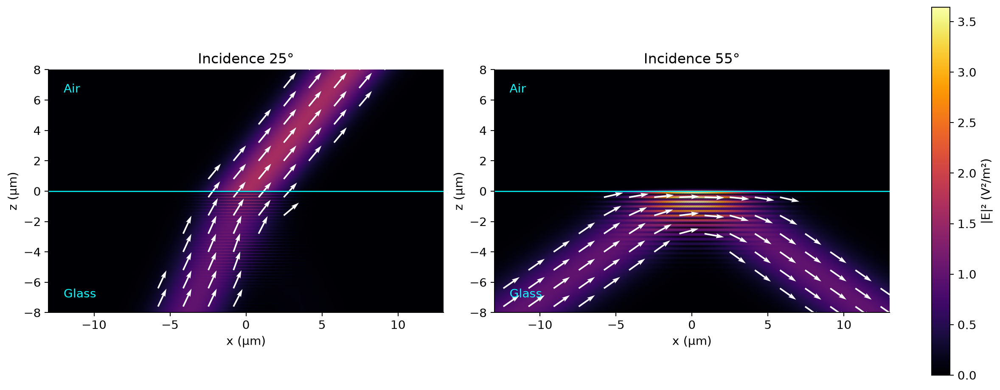

In [3]:
def gaussian_beam(angle, waist=3 * um, count=61):
    spread = 2 / (2 * np.pi * n1 / wavelength * waist)
    theta = angle + np.linspace(-4 * spread, 4 * spread, count)
    amplitudes = np.exp(-(((theta - angle) / spread) ** 2))
    amplitudes /= amplitudes.sum()
    directions = np.column_stack((np.sin(theta), np.zeros(count), np.cos(theta)))
    electric = np.zeros((count, 3), dtype=complex)
    electric[:, 1] = amplitudes

    return optics.PlaneWaveExpansion(
        2 * np.pi * n1 / wavelength * directions, electric, [0, 0, 0], wavelength, glass
    )


x = np.linspace(-13, 13, 221) * um
z = np.linspace(-8, 8, 161) * um
X, Z = np.meshgrid(x, z)
points = np.stack((X, np.zeros_like(X), Z), axis=-1)
below = Z <= 0
beam_maps = []

for degrees in (25, 55):
    source = gaussian_beam(np.deg2rad(degrees))
    solution = optics.scatter_plane(source, interface)
    electric = np.zeros(points.shape, dtype=complex)
    flow = np.zeros(points.shape)

    for mask, side in ((below, "minus"), (~below, "plus")):
        field = solution.evaluate(optics.PointGrid(points[mask]), side=side)
        electric[mask] = field.electric.values
        flow[mask] = field.poynting()

    beam_maps.append((electric, flow))

peak = max(np.max(np.sum(abs(electric) ** 2, axis=-1)) for electric, _ in beam_maps)
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")

for ax, degrees, (electric, flow) in zip(axes, (25, 55), beam_maps):
    norm = np.sum(abs(electric) ** 2, axis=-1)
    image = ax.pcolormesh(
        x / um, z / um, norm, cmap="inferno", vmin=0, vmax=peak, shading="gouraud"
    )
    ax.axhline(0, color="cyan", lw=1)
    ax.text(-12, -7, "Glass", color="cyan")
    ax.text(-12, 6.5, "Air", color="cyan")

    step = (slice(4, None, 12), slice(5, None, 14))
    direction = flow / np.maximum(np.linalg.norm(flow, axis=-1, keepdims=True), 1e-30)
    visible = norm[step] > 0.06 * peak
    ax.quiver(
        X[step][visible] / um,
        Z[step][visible] / um,
        direction[step][visible, 0],
        direction[step][visible, 2],
        color="white",
        scale=20,
        width=0.004,
    )
    ax.set(
        xlabel="x (µm)", ylabel="z (µm)", title=f"Incidence {degrees}°", aspect="equal"
    )

fig.colorbar(image, ax=axes, label="|E|² (V²/m²)")
plt.show()

At 25° the transmitted beam bends away from the normal as it enters lower-index
air. At 55° the incident and reflected beams interfere in glass, while only a
thin evanescent layer appears in air. A narrower waist broadens the angular
spectrum: near the critical angle, some components can transmit while others
undergo total internal reflection.

## The evanescent field is nonzero, and its electric vector rotates

For a single p-polarized wave above critical incidence, $k_z=i\kappa$.
The amplitude penetration length is $1/\kappa$, while $|E|^2$ decays twice as
fast. The longitudinal and tangential electric components are in quadrature.

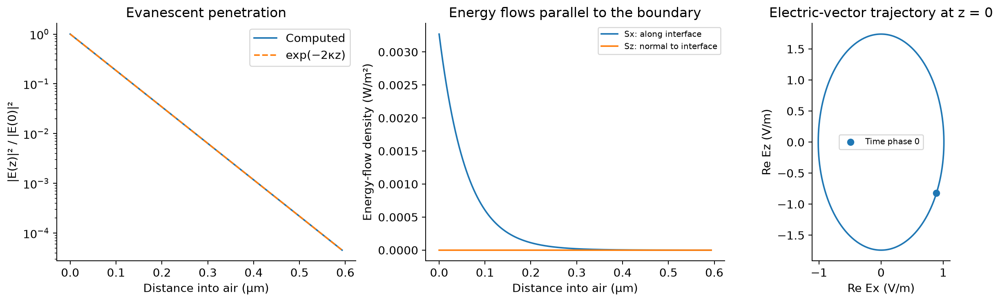

Amplitude penetration length: 0.119 µm


In [4]:
angle = np.deg2rad(55)
tir = optics.scatter_plane(plane_wave(angle, "p"), interface)
kappa = tir.transmitted.wavevectors[0, 2].imag
penetration = 1 / kappa
heights = np.linspace(0, 5 * penetration, 150)
line = optics.PointGrid(
    np.column_stack((np.zeros_like(heights), np.zeros_like(heights), heights))
)
field = tir.transmitted.evaluate(line)

phase = np.linspace(0, 2 * np.pi, 300)
E0 = field.electric.values[0]
ellipse = np.real(E0[:, None] * np.exp(-1j * phase))

fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout="constrained")
axes[0].semilogy(
    heights / um, field.electric.norm2() / field.electric.norm2()[0], label="Computed"
)
axes[0].semilogy(heights / um, np.exp(-2 * kappa * heights), "--", label="exp(−2κz)")
axes[0].set(
    xlabel="Distance into air (µm)",
    ylabel="|E(z)|² / |E(0)|²",
    title="Evanescent penetration",
)
axes[0].legend()

flow = field.poynting()
axes[1].plot(heights / um, flow[:, 0], label="Sx: along interface")
axes[1].plot(heights / um, flow[:, 2], label="Sz: normal to interface")
axes[1].set(
    xlabel="Distance into air (µm)",
    ylabel="Energy-flow density (W/m²)",
    title="Energy flows parallel to the boundary",
)
axes[1].legend(fontsize=8)

axes[2].plot(ellipse[0], ellipse[2])
axes[2].scatter(ellipse[0, 0], ellipse[2, 0], label="Time phase 0")
axes[2].set(
    xlabel="Re Ex (V/m)",
    ylabel="Re Ez (V/m)",
    title="Electric-vector trajectory at z = 0",
    aspect="equal",
)
axes[2].legend(fontsize=8)
plt.show()

assert_allclose(flow[:, 2], 0, atol=1e-15)
print(f"Amplitude penetration length: {penetration / um:.3f} µm")

**Try next:** change the beam angle to 40°, reduce its waist, or replace glass–air
with air–glass. Compare s and p finite beams. The API sequence stays the same:
construct a modal source, call `scatter_plane`, then evaluate each physical side.
Exactly critical or grazing incidence is excluded by the present solver; approach
those angles from either side rather than evaluating the singular representation.

## Total internal reflection acts as a retarder

A linearly polarized plane wave contains equal s and p amplitudes and strikes a glass–air interface at 55°, above the critical angle. Reflection preserves the total power but gives s and p different phases, creating elliptical polarization.

To compare the actual polarization transverse to each ray, each observation grid uses its own right-handed `(s, p, propagation)` frame. These are cross sections of the separate incident and reflected waves, not the interference pattern of their sum.

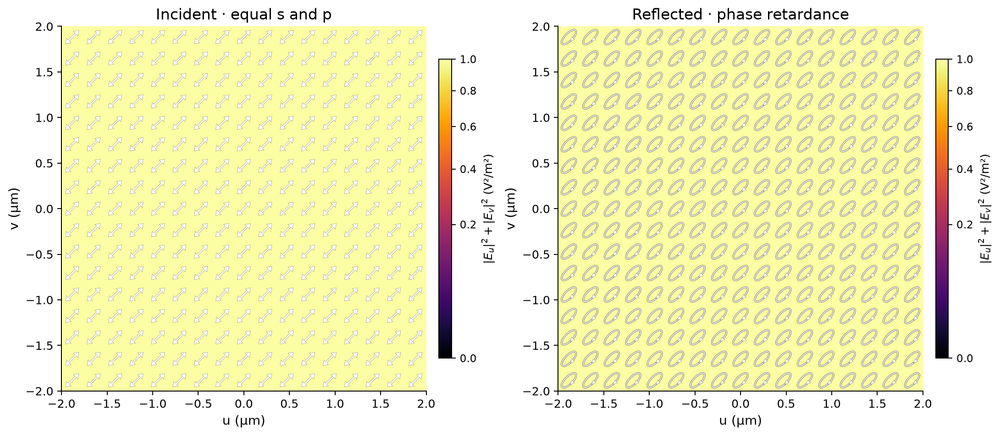

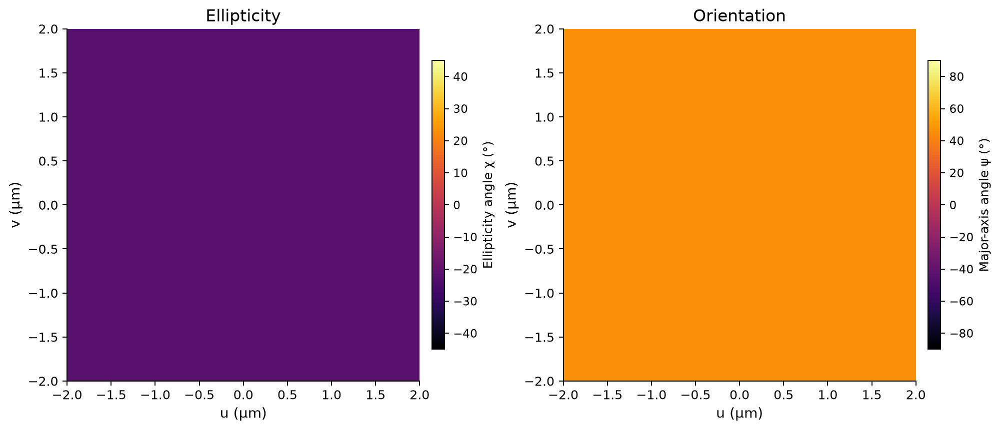

In [5]:
from vecdiff_general.visualization import (
    animate_polarization,
    plot_polarization,
    plot_polarization_scalar,
)

um = 1e-6
wavelength = 532e-9
air = optics.HomogeneousRegion("air", optics.Dielectric(1.0))

glass = optics.HomogeneousRegion("glass", optics.Dielectric(1.5))
interface = optics.PlanarInterface(optics.Frame(), glass, air)
angle = np.deg2rad(55)

direction = np.array([np.sin(angle), 0, np.cos(angle)])
s = np.array([0.0, 1.0, 0.0])
p = np.cross(direction, s)
incident_vector = (s + p) / np.sqrt(2)

source = optics.PlaneWaveExpansion(
    (2 * np.pi * 1.5 / wavelength * direction)[None, :],
    incident_vector[None, :],
    [0, 0, 0],
    wavelength,
    glass,
)
scattering = optics.scatter_plane(source, interface)
reflected_direction = np.array([np.sin(angle), 0, -np.cos(angle)])
reflected_p = np.cross(reflected_direction, s)

section_axis = np.linspace(-2, 2, 101) * um
incident_grid = optics.CartesianGrid(
    section_axis,
    section_axis,
    optics.Frame(basis=np.column_stack((s, p, direction))),
)
reflected_grid = optics.CartesianGrid(
    section_axis,
    section_axis,
    optics.Frame(basis=np.column_stack((s, reflected_p, reflected_direction))),
)
incident_field = source.evaluate(incident_grid)
reflected_field = scattering.reflected.evaluate(reflected_grid)

figure, axes = plt.subplots(1, 2, figsize=(12, 5.7), layout="constrained")

for axis, current_field, title in zip(
    axes,
    (incident_field, reflected_field),
    ("Incident · equal s and p", "Reflected · phase retardance"),
):
    plot_polarization(current_field, axis=axis, title=title, density=1.25)
plt.show()

figure, axes = plt.subplots(1, 2, figsize=(11, 5), layout="constrained")
plot_polarization_scalar(reflected_field, "ellipticity", axis=axes[0])
plot_polarization_scalar(reflected_field, "orientation", axis=axes[1])
plt.show()

## Read the rotation directly

Each electric arrow starts at the fixed center of its polarization ellipse and
ends at $\mathrm{Re}(\mathbf E e^{-i\omega t})$, with its head aligned with the
shaft. The relative phase between components and the spatial phase are retained.
There are no point markers. A linear arrow reaches full length at a turning point
and disappears at a zero crossing. Glyph lengths are normalized for display;
the background gives the projected field magnitude.

In [6]:
from IPython.display import HTML, display

animation = animate_polarization(
    reflected_field,
    frames=32,
    density=0.6,
    figsize=(5.6, 5.4),
    title="Reflected polarization · one optical cycle",
)
display(HTML(animation.to_jshtml()))
plt.close()